In [1]:
import os
import subprocess
import cv2

ss_ready = (
    hasattr(cv2, "ximgproc")
    and hasattr(cv2.ximgproc, "segmentation")
)

if not ss_ready:
    print("Installing OpenCV with Selective Search support...")

    subprocess.run(
        "pip uninstall -y -q opencv-python "
        "opencv-python-headless opencv-contrib-python "
        "opencv-contrib-python-headless",
        shell=True,
        check=False
    )

    subprocess.run(
        "pip install -q opencv-contrib-python",
        shell=True,
        check=True
    )

    print("Installation complete. Restarting runtime...")
    os.kill(os.getpid(), 9)
else:
    print("Selective Search is already available!")

Selective Search is already available!


In [2]:
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import (
    preprocess_input,
    decode_predictions
)
import numpy as np
import cv2
from google.colab import files
from google.colab.patches import cv2_imshow

In [3]:
model = VGG16(
    weights="imagenet",
    include_top=True
)

print("VGG16 model loaded successfully!")

553467096/553467096 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
VGG16 model loaded successfully!


In [4]:
def get_region_proposals(img, max_regions=200):

    try:
        ss = cv2.ximgproc.segmentation.createSelectiveSearchSegmentation()

        ss.setBaseImage(img)

        ss.switchToSelectiveSearchFast()

        boxes = [
            (x, y, w, h)
            for (x, y, w, h) in ss.process()
            if w > 40 and h > 40
        ]

        if boxes:
            return boxes[:max_regions]

    except Exception:
        pass

    # Fallback: sliding windows
    H, W = img.shape[:2]
    boxes = []

    for s in (0.6, 0.4, 0.25):
        bw, bh = int(W * s), int(H * s)

        for y in range(0, H - bh + 1, max(1, bh // 2)):
            for x in range(0, W - bw + 1, max(1, bw // 2)):
                boxes.append((x, y, bw, bh))

    return boxes[:max_regions]

In [5]:
def non_max_suppression(dets, iou_thr=0.3):

    if not dets:
        return []

    # Convert boxes into corner coordinates
    boxes = np.array([
        [x, y, x + w, y + h]
        for (x, y, w, h), _, _ in dets
    ], dtype=float)

    # Get confidence scores
    scores = np.array([
        score for _, _, score in dets
    ])

    # Sort detections from highest to lowest score
    order = scores.argsort()[::-1]
    keep = []

    while len(order):
        i = order[0]
        keep.append(i)

        rest = order[1:]

        # Find intersection coordinates
        xx1 = np.maximum(boxes[i, 0], boxes[rest, 0])
        yy1 = np.maximum(boxes[i, 1], boxes[rest, 1])
        xx2 = np.minimum(boxes[i, 2], boxes[rest, 2])
        yy2 = np.minimum(boxes[i, 3], boxes[rest, 3])

        # Calculate intersection area
        w = np.clip(xx2 - xx1, 0, None)
        h = np.clip(yy2 - yy1, 0, None)
        inter = w * h

        # Calculate areas of the boxes
        area_i = (
            (boxes[i, 2] - boxes[i, 0])
            * (boxes[i, 3] - boxes[i, 1])
        )

        area_r = (
            (boxes[rest, 2] - boxes[rest, 0])
            * (boxes[rest, 3] - boxes[rest, 1])
        )

        # Calculate IoU
        iou = inter / (area_i + area_r - inter + 1e-9)

        # Keep boxes that overlap less than the threshold
        order = rest[iou < iou_thr]

    return [dets[i] for i in keep]

Saving ocean.jpg to ocean.jpg
Number of regions: 200
35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Final detections: 5


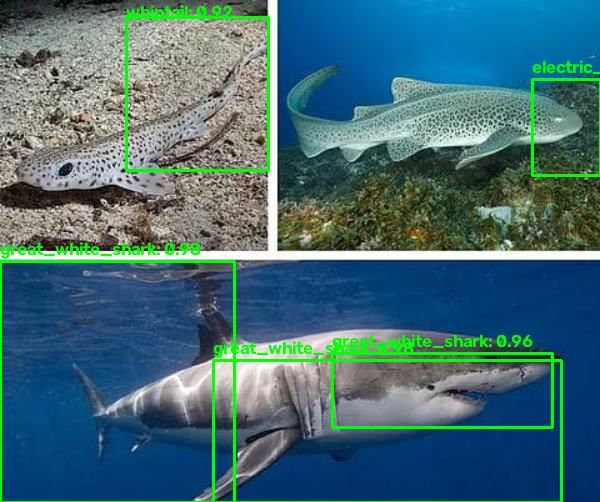

In [6]:
# Upload image
uploaded = files.upload()
image_path = next(iter(uploaded))

# Read image
img = cv2.imread(image_path)

if img is None:
    raise ValueError("Could not read the uploaded image.")

# Store original dimensions
H0, W0 = img.shape[:2]

# Resize image to width 600 for faster processing
img = cv2.resize(
    img,
    (600, int(H0 * 600.0 / W0))
)

# Generate region proposals
boxes = get_region_proposals(img, max_regions=200)

print("Number of regions:", len(boxes))

# Crop each proposed region and resize it to 224 x 224
crops = np.array([
    cv2.resize(
        cv2.cvtColor(img[y:y+h, x:x+w], cv2.COLOR_BGR2RGB),
        (224, 224)
    )
    for (x, y, w, h) in boxes
], dtype=np.float32)

if len(crops) == 0:
    raise ValueError("No region proposals were generated.")

# Classify all regions in batches
preds = model.predict(
    preprocess_input(crops),
    batch_size=32,
    verbose=0
)

# Keep high-confidence detections
detections = []

for (x, y, w, h), p in zip(boxes, preds):
    _, label, prob = decode_predictions(
        p[None, ...],
        top=1
    )[0][0]

    if prob > 0.90:
        detections.append(((x, y, w, h), label, float(prob)))

# Remove duplicate boxes
detections = non_max_suppression(detections, iou_thr=0.3)

print("Final detections:", len(detections))

# Draw bounding boxes and labels
for (x, y, w, h), label, score in detections:
    cv2.rectangle(
        img,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

    cv2.putText(
        img,
        f"{label}: {score:.2f}",
        (x, max(18, y - 6)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (0, 255, 0),
        2
    )

# Display final output
cv2_imshow(img)